# SONG as UMAP initialization: preliminary MNIST evidence

Executed figures and tables supporting [the draft preprint](../preprint/SONG_initialized_UMAP.md). One seed (42), 60,000 train / 10,000 test.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT=Path.cwd()
results=pd.read_csv(ROOT/'reports/song_umap_initialization.csv')
results[['method','umap_fit_s','song_fit_plus_core_s','total_embedding_fit_s','umap_test_transform_s','heldout_5nn_accuracy']].round(3)

,method,umap_fit_s,song_fit_plus_core_s,total_embedding_fit_s,umap_test_transform_s,heldout_5nn_accuracy
0,"UMAP spectral, 11 epochs",3.055,0.000,3.055,0.791,0.862
1,"SONG init, 11 epochs",2.091,5.592,7.683,0.799,0.929
2,"UMAP spectral, 50 epochs",5.547,0.000,5.547,1.105,0.961
3,"SONG init, 50 epochs",5.058,5.592,10.650,0.980,0.960
4,UMAP standard defaults,17.042,0.000,17.042,2.184,0.964


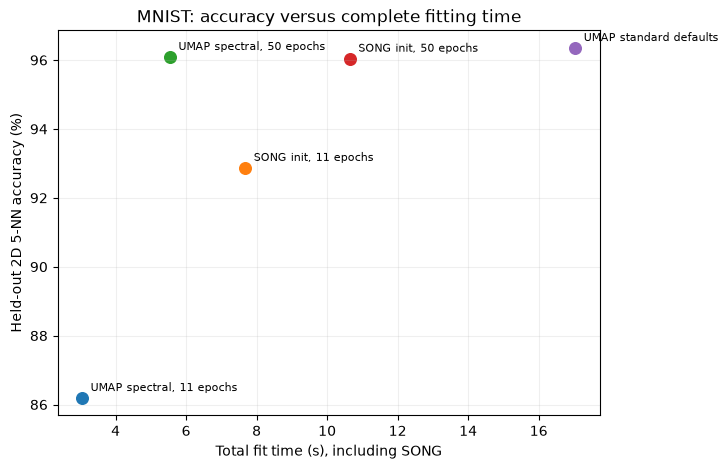

In [2]:
fig,ax=plt.subplots(figsize=(7,5))
for _,r in results.iterrows():
    ax.scatter(r.total_embedding_fit_s,r.heldout_5nn_accuracy*100,s=70)
    ax.annotate(r.method,(r.total_embedding_fit_s,r.heldout_5nn_accuracy*100),xytext=(6,5),textcoords='offset points',fontsize=8)
ax.set(xlabel='Total fit time (s), including SONG',ylabel='Held-out 2D 5-NN accuracy (%)',title='MNIST: accuracy versus complete fitting time')
ax.grid(alpha=.2)
plt.show()

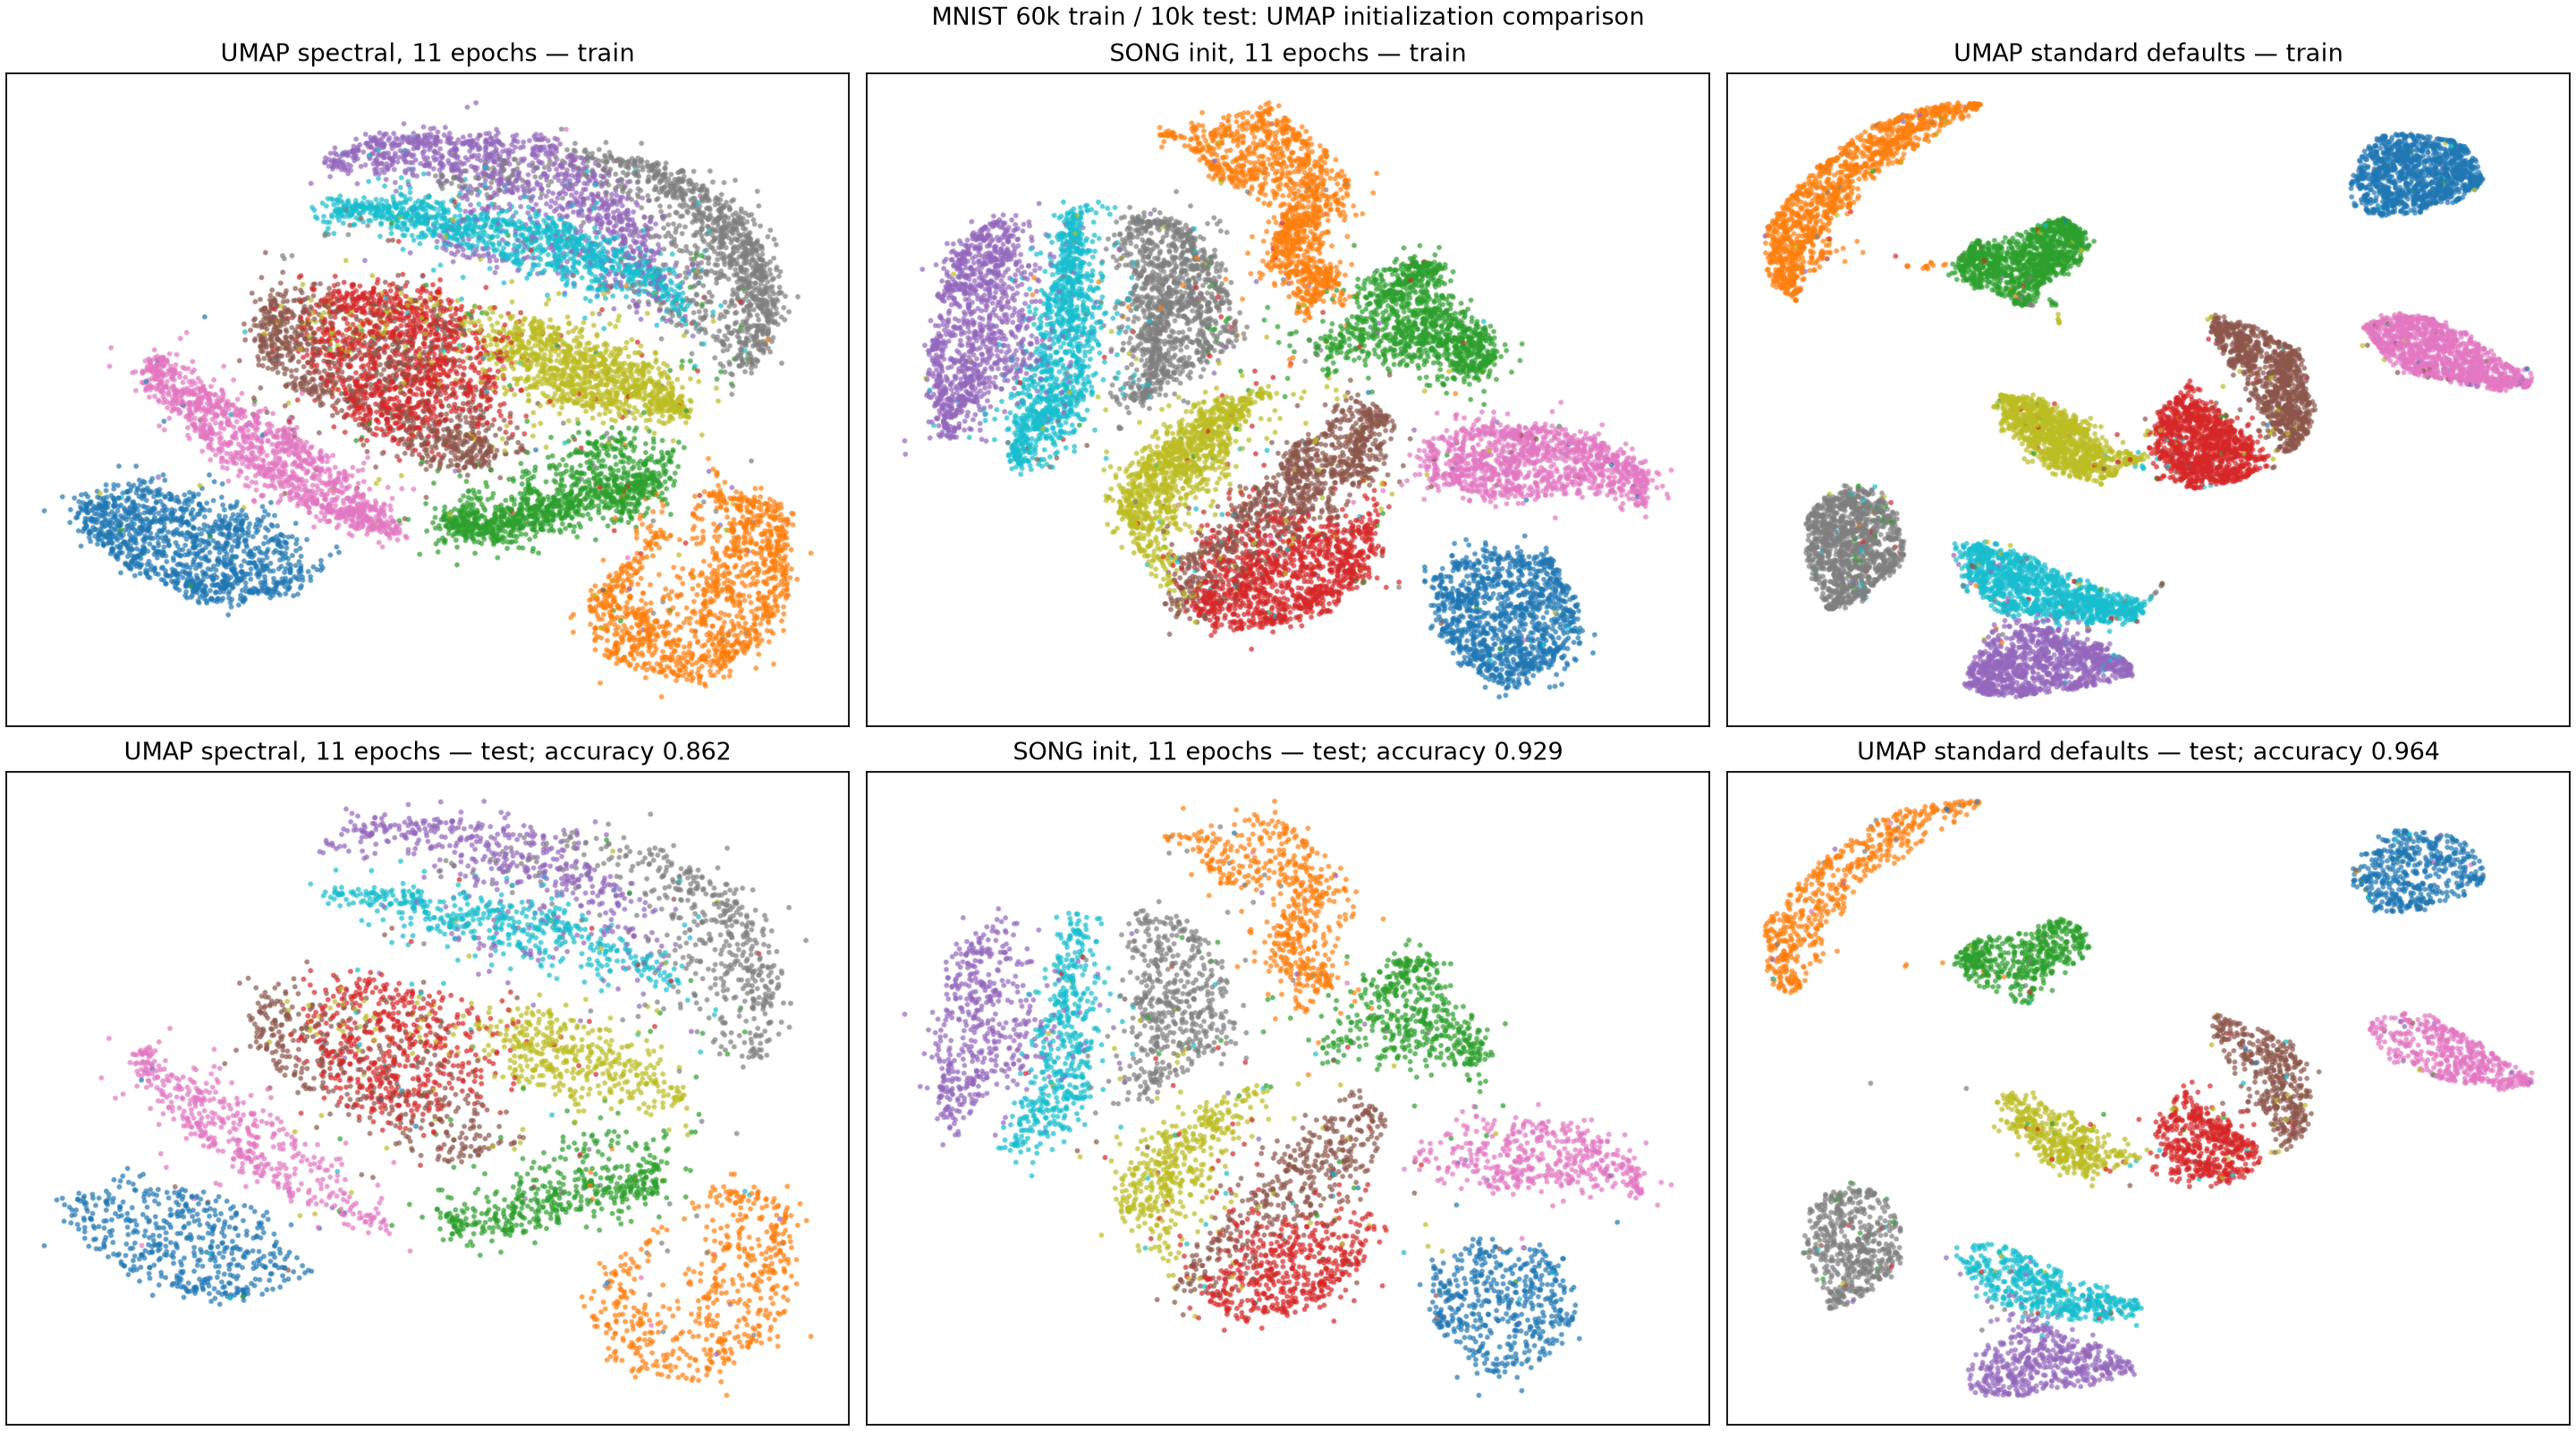

In [3]:
display(Image(filename=str(ROOT/'reports/figures/song_umap_initialization_mnist.png'),width=1000))

## Ordered heterogeneous addition

Old digits 0–4; new digits 5–9. SONG is updated on new images. UMAP transforms new images while keeping the old embedding fixed. In this run UMAP `update` raised `ZeroDivisionError`.

In [4]:
increment=json.loads((ROOT/'reports/song_increment_mnist.json').read_text())
pd.DataFrame({'SONG incremental fit':increment['song'],'UMAP transform':increment['umap']})

,SONG incremental fit,UMAP transform
old_fit_s,1.082237,7.603754
new_fit_s,1.956792,NaN
prototypes_after,1783.000000,NaN
aligned_procrustes_disparity_1000,0.658153,0.0
old_neighbor_overlap_at_15,0.081733,1.0
transform_new_s,NaN,6.126027
update_s,NaN,None
update_error,NaN,ZeroDivisionError: division by zero


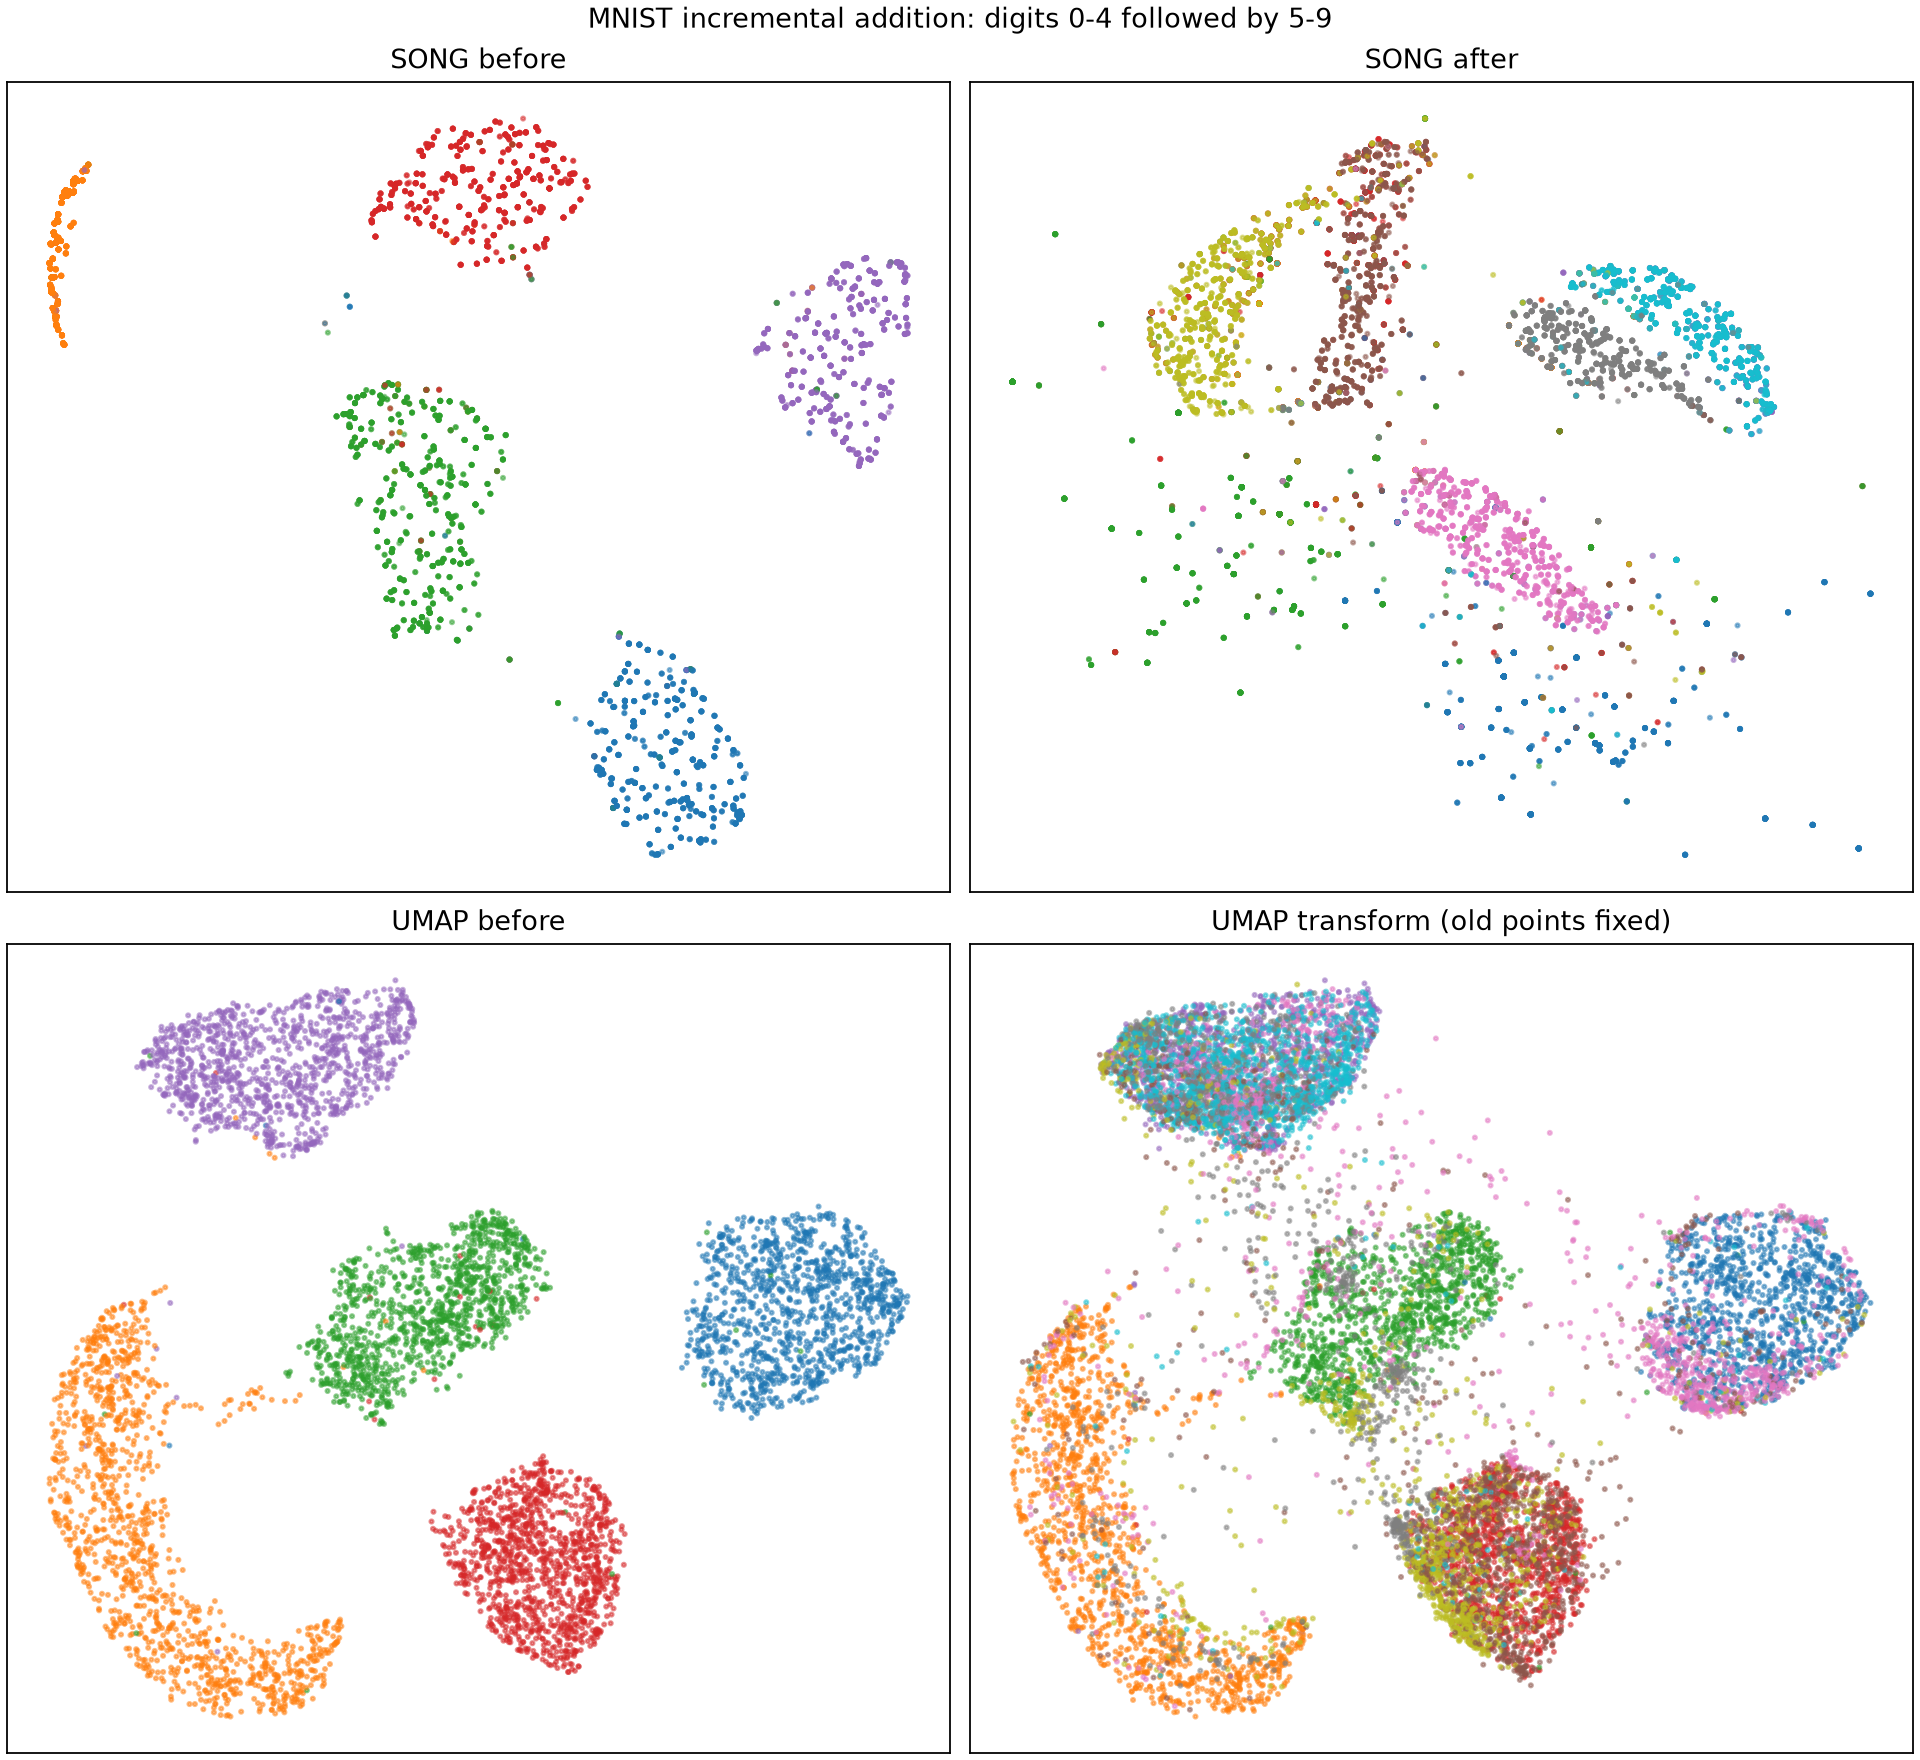

In [5]:
display(Image(filename=str(ROOT/'reports/figures/song_increment_mnist.png'),width=1000))

## Prototype search microbenchmark

Exact 10,000-query search among 1,557 prototypes. This is a component benchmark, not end-to-end fitting time.

In [6]:
search=pd.read_csv(ROOT/'reports/prototype_search_bench.csv')
search['milliseconds']=search.median_seconds*1000
search[['method','milliseconds','mismatch_count']].round(3)

,method,milliseconds,mismatch_count
0,SONG Numba brute force,40.267,0
1,BLAS matrix product,11.455,0
2,SciPy cKDTree (4 workers),40.893,0
3,scikit-learn ArgKmin,7.384,0


**Interpretation:** SONG initialization improves accuracy at 11 UMAP epochs, but incurs more total fitting time. The current SONG incremental core strongly changes old neighborhoods. A hybrid incremental embedding has not yet been implemented or evaluated.

## Rehearsal frontier and knowledge retention

Old digits 0–4 are fitted first. New digits 5–9 are added with nested replay fractions of the old training set. The retention KL compares old-anchor neighborhood distributions before and after the update; it is a diagnostic, not yet part of SONG training.

In [7]:
rehearsal=json.loads((ROOT/'reports/song_rehearsal_optimization.json').read_text())
frontier=pd.DataFrame(rehearsal['conditions'])
frontier[['rehearsal_fraction_of_old','increment_fit_s','old_class_5nn_accuracy','normalized_old_class_centroid_rms_drift','old_anchor_neighborhood_kl_nats','meets_example_target']].round(3)

,rehearsal_fraction_of_old,increment_fit_s,old_class_5nn_accuracy,normalized_old_class_centroid_rms_drift,old_anchor_neighborhood_kl_nats,meets_example_target
0,0.00,1.898,0.908,0.691,0.250,False
1,0.05,1.953,0.941,0.425,0.200,False
2,0.10,1.981,0.952,0.315,0.162,False
3,0.20,2.129,0.960,0.230,0.118,False
4,0.35,2.320,0.967,0.212,0.082,False
5,0.50,2.420,0.970,0.256,0.109,False
6,0.75,2.728,0.974,0.175,0.063,True
7,1.00,2.959,0.975,0.183,0.068,True


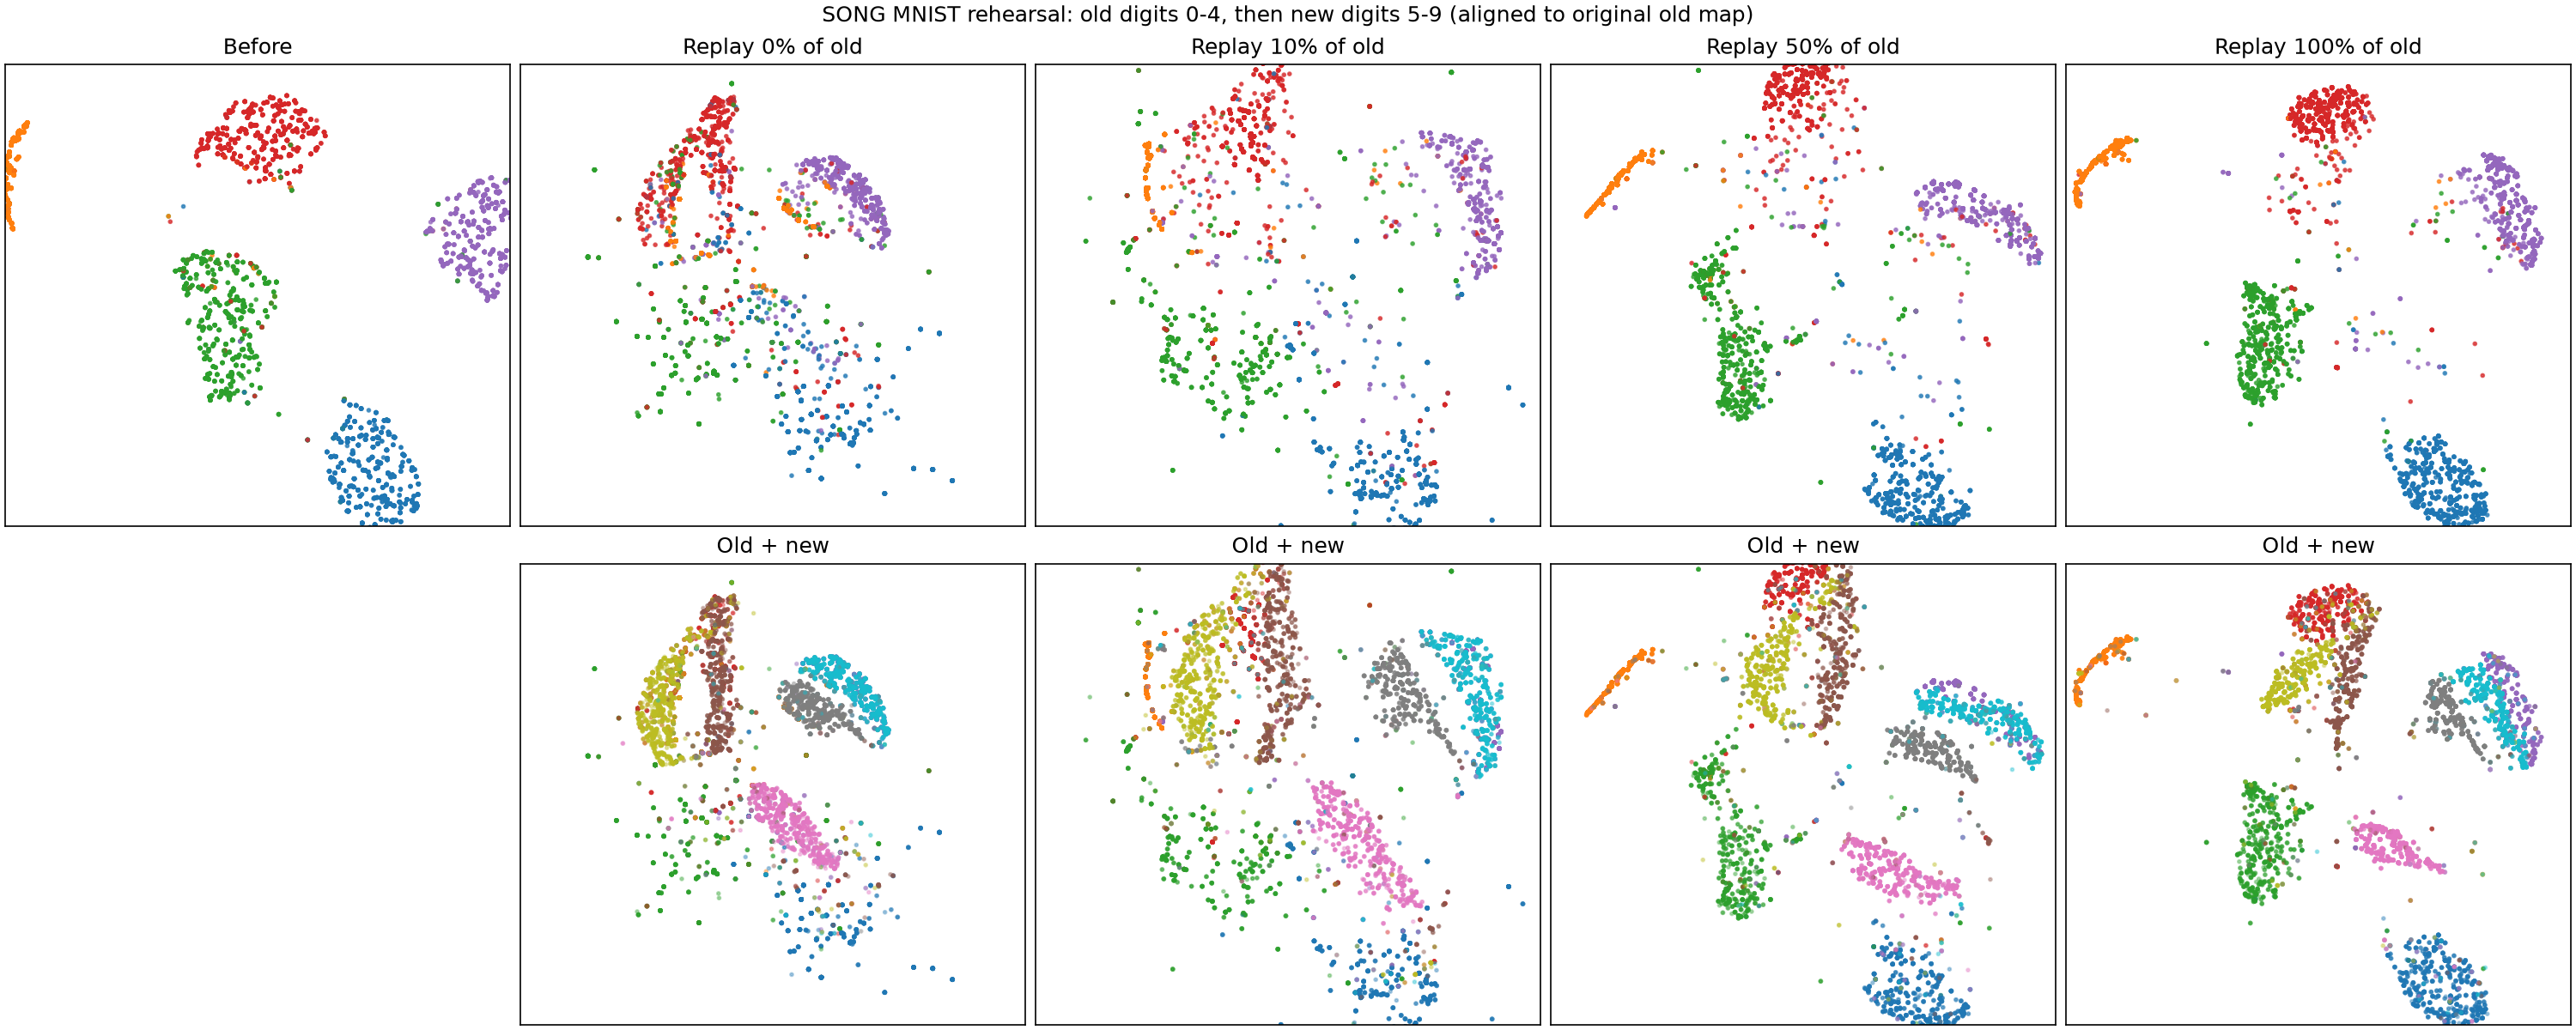

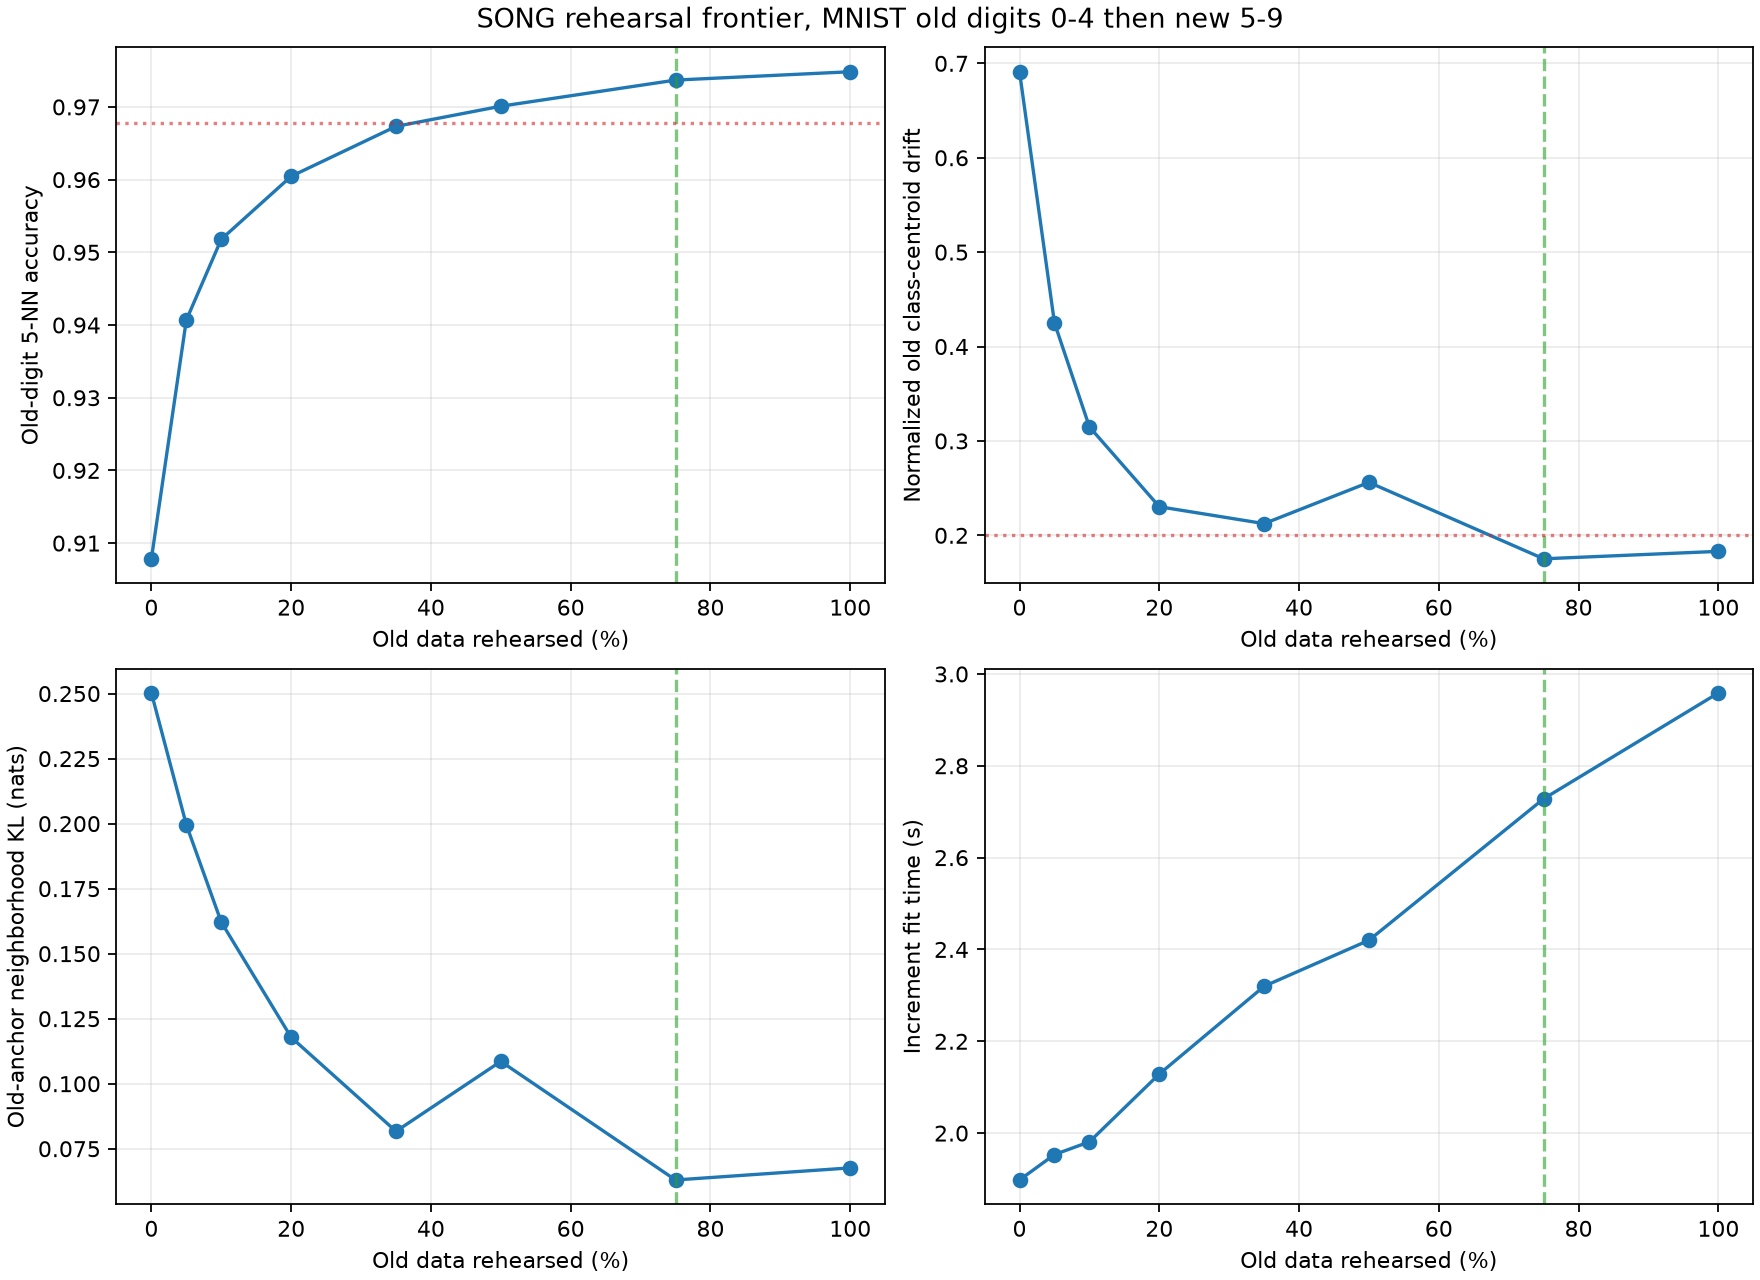

In [8]:
display(Image(filename=str(ROOT/'reports/figures/song_rehearsal_mnist.png'),width=1100))
display(Image(filename=str(ROOT/'reports/figures/song_rehearsal_tradeoff.png'),width=900))

## Novelty diagnostics

Nearest-prototype distance is available before updating. Position KL compares a vector’s coordinates under the old and updated maps, so it is available only after the update. Soft assignment KL to old prototype occupancy performed poorly on this split.

In [9]:
pd.Series(rehearsal['preupdate_novelty']).to_frame('value')

,value
old_test_n,5139
new_test_n,4861
nearest_prototype_squared_distance_auroc,0.880708
assignment_to_old_occupancy_kl_auroc,0.463759
temperature,0.960529
distance_old_median,13.707756
distance_new_median,27.323311
postupdate_position_gaussian_kl_auroc,0.757823
postupdate_position_kl_old_median,0.012119
postupdate_position_kl_new_median,0.056148


## Implemented KL coordinate refinement

The new opt-in SONG refinement minimizes old-anchor neighborhood KL and Gaussian-position KL after an incremental fit. It adjusts output prototype coordinates, not input coding vectors. Matched models below share the same initial SONG state.

In [10]:
retention=json.loads((ROOT/'reports/song_retention_kl_mnist.json').read_text())
retention_table=pd.DataFrame(retention['conditions'])
retention_table[['condition','update_fit_s','old_class_5nn_accuracy','new_class_5nn_accuracy','normalized_old_class_centroid_rms_drift','anchor_neighborhood_kl_nats','meets_example_target']].round(3)

,condition,update_fit_s,old_class_5nn_accuracy,new_class_5nn_accuracy,normalized_old_class_centroid_rms_drift,anchor_neighborhood_kl_nats,meets_example_target
0,No replay; no KL,2.059,0.908,0.956,0.681,0.296,False
1,No replay; neighborhood KL,2.468,0.908,0.956,0.211,0.025,False
2,No replay; neighborhood + position KL,2.352,0.903,0.955,0.208,0.025,False
3,10% replay; no KL,2.074,0.952,0.957,0.323,0.160,False
4,10% replay; neighborhood + position KL,2.270,0.949,0.954,0.112,0.006,False
5,20% replay; neighborhood + position KL,2.369,0.960,0.956,0.076,0.010,False
6,35% replay; no KL,2.327,0.969,0.953,0.226,0.089,False
7,35% replay; neighborhood + position KL,2.448,0.969,0.951,0.092,0.002,True
8,50% replay; no KL,2.547,0.969,0.948,0.191,0.071,True
9,50% replay; neighborhood + position KL,2.671,0.970,0.951,0.093,0.001,True


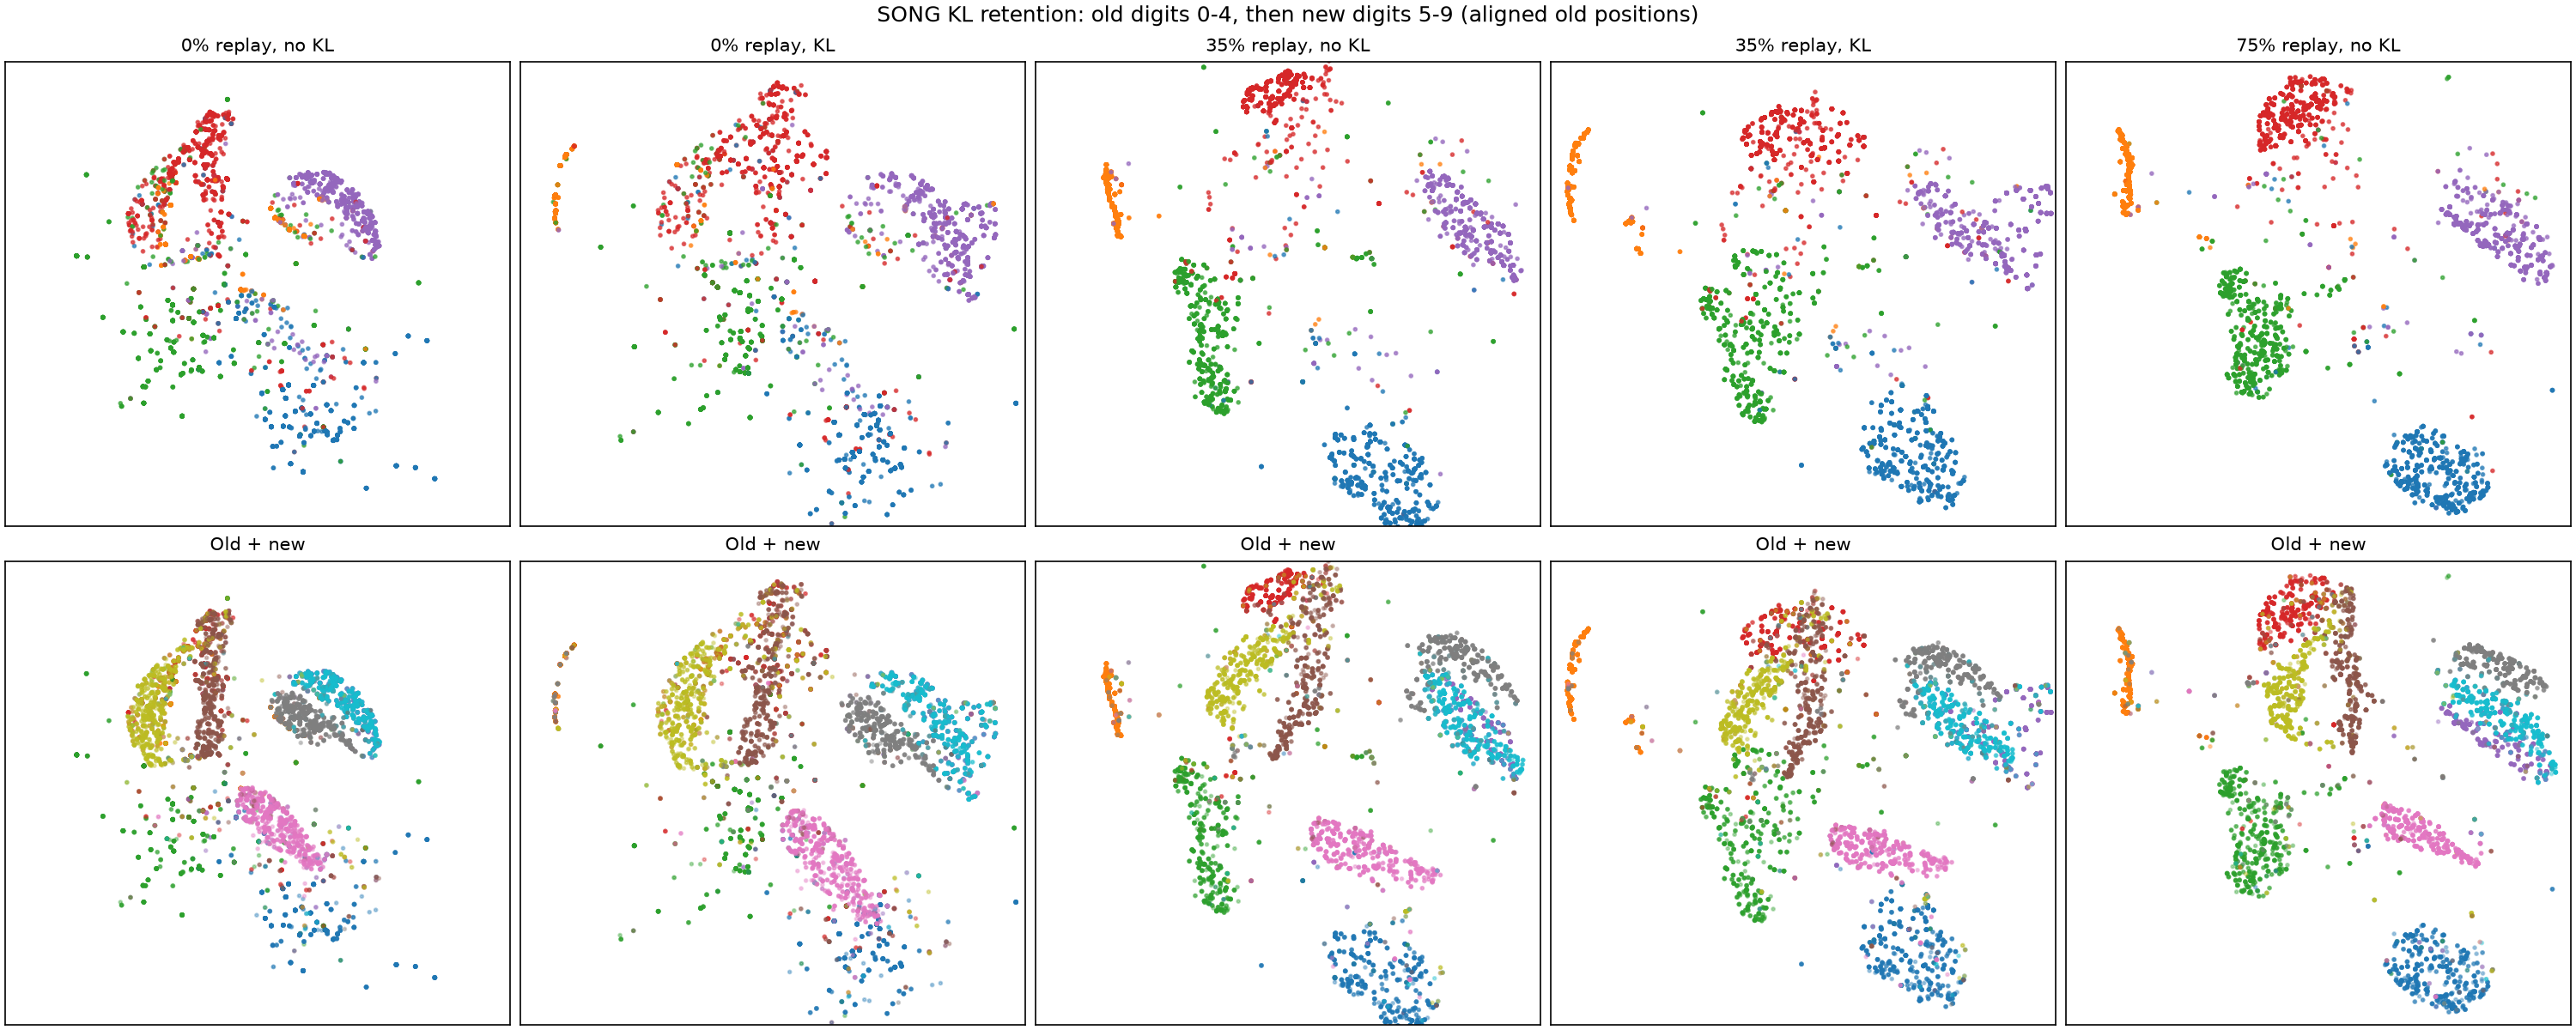

In [11]:
display(Image(filename=str(ROOT/'reports/figures/song_retention_kl_mnist.png'),width=1100))

At 35% replay, KL improves class-position drift while leaving old-digit accuracy unchanged. Without rehearsal, KL alone does not preserve old-class identity because SONG coding vectors still move.

### Three-seed retention check

KL lowers class-centroid drift across seeds 42–44, while the 35% replay target passes in only one seed. The sample is too small to establish a reliable replay-memory reduction.

In [12]:
seeds=pd.read_csv(ROOT/'reports/song_retention_kl_seeds.csv')
seeds[['seed','rehearsal_fraction','kl_enabled','old_accuracy_drop_pp','old_centroid_drift','fit_s','meets_example_target']].round(3)

,seed,rehearsal_fraction,kl_enabled,old_accuracy_drop_pp,old_centroid_drift,fit_s,meets_example_target
0,42,0.35,False,0.882,0.226,2.251,False
1,42,0.35,True,0.882,0.092,2.421,True
2,42,0.50,False,0.899,0.191,2.449,True
3,42,0.50,True,0.801,0.093,2.630,True
4,43,0.35,False,1.405,0.262,2.261,False
5,43,0.35,True,1.585,0.113,2.450,False
6,43,0.50,False,1.242,0.200,2.385,False
7,43,0.50,True,1.062,0.107,2.557,False
8,44,0.35,False,1.242,0.183,2.266,False
9,44,0.35,True,1.242,0.133,2.457,False


In [13]:
seeds.groupby(['rehearsal_fraction','kl_enabled'])[['old_accuracy_drop_pp','old_centroid_drift','fit_s','meets_example_target']].agg(['mean','std']).round(3)

old_accuracy_drop_pp        old_centroid_drift  \
                                              mean    std               mean   
rehearsal_fraction kl_enabled                                                  
0.35               False                     1.176  0.267              0.224   
                   True                      1.236  0.351              0.112   
0.50               False                     0.997  0.214              0.180   
                   True                      0.915  0.134              0.098   

                                      fit_s        meets_example_target         
                                 std   mean    std                 mean    std  
rehearsal_fraction kl_enabled                                                   
0.35               False       0.040  2.259  0.007                0.000  0.000  
                   True        0.021  2.443  0.019                0.333  0.577  
0.50               False       0.028  2.413  0.033                0.667  0.577  
                   True        0.008  2.602  0.040                0.667  0.577